# A shape constraint as a check for omitted confounding

A drug that helps at every dose can still look harmful in the data. Suppose
the sickest patients are given the highest doses. Their outcomes are worse
to begin with, so high doses and poor outcomes appear together, and a model
fitted to those data reports a response that falls as the dose rises. The resulting curve can describe these patients' outcomes while failing to estimate the
effect of changing dose.

Sometimes the direction is known in advance: more of the drug does not make
a patient worse. The idea of this study is to make the model say so, by
fitting once with the dose free to take any shape and once forbidden to fall,
and to use the difference between the two fits as a diagnostic for tension
between the constraint, adjustment set, and additive specification.

This advanced case teaches how a monotonicity constraint encodes a causal assumption and
how violations can expose confounding or a misspecified adjustment set. Each simulation
reveals its known causal structure after the corresponding fit is interpreted.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether a shape constraint can reveal omitted confounding |
| **Observed response** | a simulated outcome under a known confounding structure |
| **Estimand** | the centered conditional dose–response curve at the simulated covariate means, compared with the known centered intervention curve |
| **Units** | simulated, arbitrary scale |
| **Sampling unit** | one simulated patient |
| **Time zero / follow-up** | dose assigned after baseline severity; one post-dose response |
| **Positivity** | assessed only on the simulated dose–severity support; clipping creates sparse boundary regions |
| **Dependence** | independent given the simulated confounder |
| **Split / resampling unit** | the patient |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | repeated simulation |
| **Claim type** | causal, and only because the simulation supplies the identification. On observational data the same fit would not support it |
:::


## The data

The data are simulated, so the causal curve and the confounder are both
known. Six hundred patients each receive a dose between 0 and 10 and record a
response. A severity score raises the dose a patient is given and lowers the
response. That double role is what makes it a confounder.

$$
\begin{aligned}
\text{severity} &\sim N(0, 1) \\
\text{proxy} &= 0.6\,\text{severity} + 0.8\,\varepsilon_p \\
\text{dose} &= \operatorname{clip}(5 + 1.5\,\text{severity} + \varepsilon_d,\ 0,\ 10),
  \qquad \varepsilon_d \sim N(0, 1.5^2) \\
y &= 3\log(1 + \text{dose}) - 2.5\,\text{severity} + \varepsilon_y
\end{aligned}
$$

The term that does the damage is $-2.5\,\text{severity}$: it pushes the
response down exactly when severity — and therefore dose — is high. The
causal dose-response $3\log(1+\text{dose})$ rises at every dose; severity
works against it. Sicker patients are treated harder and do worse whether or
not the drug works, which is confounding by indication
{cite}`walker1996confounding`. The proxy is correlated with severity but not
equal to it, so adjusting for it removes part of the confounding and leaves the
rest. Two further covariates affect nothing and are present throughout.

In [1]:
import collections

import warnings

import numpy as np

import polars as pl

import mboostrs as mb

n_obs = 600

def generate(rng, rows=n_obs, confounded=True, gamma=2.5, noise=1.0):
    # gamma is how hard severity pushes the response down, so it sets the
    # strength of the confounding. Everything else is held fixed.
    severity = rng.normal(0, 1, rows)
    proxy = 0.6 * severity + 0.8 * rng.normal(0, 1, rows)
    dose = (np.clip(5 + 1.5 * severity + rng.normal(0, 1.5, rows), 0, 10)
            if confounded else rng.uniform(0, 10, rows))
    response = (3 * np.log1p(dose) - gamma * severity
                + rng.normal(0, noise, rows))
    return {
        "dose": dose,
        "proxy": proxy,
        "severity": severity,
        "age": rng.normal(60, 10, rows),
        "weight": rng.normal(75, 12, rows),
        "y": response,
    }

rng = np.random.default_rng(2026)


In [2]:
data = generate(rng)

grid_dose = np.linspace(0, 10, 60)

causal_curve = 3 * np.log1p(grid_dose)

causal_curve = causal_curve - causal_curve.mean()

print(f"n = {n_obs}")

print(f"corr(dose, severity) {np.corrcoef(data['dose'], data['severity'])[0, 1]:.3f}")

print(f"corr(proxy, severity) {np.corrcoef(data['proxy'], data['severity'])[0, 1]:.3f}")

print(f"corr(dose, y)        {np.corrcoef(data['dose'], data['y'])[0, 1]:.3f}"
      f"   (the causal effect is positive at every dose)")

corr_dose_y = f"{np.corrcoef(data['dose'], data['y'])[0, 1]:.3f}"

corr_proxy_severity = f"{np.corrcoef(data['proxy'], data['severity'])[0, 1]:.2f}"


n = 600
corr(dose, severity) 0.713
corr(proxy, severity) 0.646
corr(dose, y)        -0.266   (the causal effect is positive at every dose)


In the sample, dose and response correlate {eval}`corr_dose_y`, while the drug
raises the response at every dose. The negative sign is severity's doing: it
pushes the dose up and the response down. The proxy correlates
{eval}`corr_proxy_severity` with severity, which is why adjusting for it removes
part of the confounding and not all of it.


## Free and monotone fits

An adjustment set is the group of variables a model holds fixed when it
compares patients on different doses. Three are used here: none, the proxy,
and severity itself (available only because the data are simulated). Each is
fitted twice. Once with `bbs(dose, df=4)`, a P-spline free to take any shape.
Once with `bmono(dose, df=4, constraint='increasing')`, the same spline with
its coefficients restricted so the fitted curve never falls
{cite}`hofner2011monotonicity`.

`bmono` offers two inner solvers, and the whole test below rests on the
constraint not leaking a downward slope. The default, `type='quad.prog'`,
solves each step exactly, so the constraint holds at every iteration count.
`type='iterative'` adds a large penalty for violating it and iterates until
the coefficients settle; that is much faster per step, but a small violation
survives each boosting step, always in the same direction, and the steps add up.
This study passes `type='quad.prog'` explicitly, though it is now the default.

In [3]:
check_rng = np.random.default_rng(0)
falling = {"x": check_rng.uniform(0, 10, 400)}
falling["y"] = -0.5 * falling["x"] + check_rng.normal(0, 1, 400)
check_grid = {"x": np.linspace(0, 10, 50)}
# Fix the random draw so the resampling result is reproducible.
violations = []
for solver in ("iterative", "quad.prog"):
    model = mb.gamboost(
        f"y ~ bmono(x, df=4, constraint='increasing', type='{solver}')",
        data=falling, family=mb.Gaussian(), control=mb.boost_control(2000, 0.1),
    )
    for stop in (10, 100, 300, 2000):
        curve = np.asarray(model[:stop].predict(newdata=check_grid)).ravel()
        steps = np.diff(curve)
        violations.append({
            "solver": solver,
            "mstop": stop,
            "cumulative decrease": round(float(steps[steps < 0].sum()), 4),
        })

display(pl.DataFrame(violations))

drift = {(v["solver"], v["mstop"]): v["cumulative decrease"] for v in violations}
iterative_10 = f"{abs(drift[('iterative', 10)]):.3f}"
iterative_2000 = f"{abs(drift[('iterative', 2000)]):.3f}"
exact_worst = f"{max(abs(drift[('quad.prog', m)]) for m in (10, 100, 300, 2000)):.3f}"


solver,mstop,cumulative decrease
str,i64,f64
"""iterative""",10,-0.0037
"""iterative""",100,-0.0366
"""iterative""",300,-0.1088
"""iterative""",2000,-0.6752
"""quad.prog""",10,0.0
"""quad.prog""",100,0.0
"""quad.prog""",300,0.0
"""quad.prog""",2000,0.0


Fitting an increasing constraint to a falling relation, the iterative solver
drops {eval}`iterative_10` in total after 10 iterations and
{eval}`iterative_2000` after 2000, where the constraint forbids any drop at all.
The exact solver holds at {eval}`exact_worst` for every iteration count.

## Results for three adjustment sets

Two shapes × three adjustment sets, each fitted by cross-validation on the
same ten folds. The table records the cross-validated mean squared error, the
average distance of the fitted curve from the causal curve over the dose
grid, the number of dose-grid intervals on which the fit falls, and how many
boosting steps each fit spent on the dose learner versus the confounder.

The chart plots four of them, with severity in the model and without, against
the curve that generated the data. Each curve is shifted to average zero: a fit
determines the shape of the dose effect but not its overall level.

In [4]:
covariates = "bols(age) + bols(weight)"

adjustments = {
    "none": "",
    "proxy": " + bbs(proxy, df=4)",
    "severity": " + bbs(severity, df=4)",
}

dose_terms = {
    "free": "bbs(dose, df=4)",
    "monotone": "bmono(dose, df=4, constraint='increasing', type='quad.prog')",
}

def dose_response(model, source):
    # Fitted response over the dose range with every other predictor held at
    # its mean, centred so it is comparable with the centred causal curve.
    grid = {"dose": grid_dose}
    for name in ("proxy", "severity", "age", "weight"):
        grid[name] = np.full(len(grid_dose), float(np.mean(source[name])))
    fitted = np.asarray(model.predict(newdata=grid)).ravel()
    return fitted - fitted.mean()

folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=1)

fits, fold_risk, rows = {}, {}, []


In [5]:
for adjustment, extra in adjustments.items():
    for shape, dose_term in dose_terms.items():
        model = mb.gamboost(f"y ~ {dose_term} + {covariates}{extra}", data=data,
                            family=mb.Gaussian(), control=mb.boost_control(600, 0.1))
        result = model.cvrisk(folds=folds)
        average = np.asarray(result.aggregate)
        stopped = model[:result.optimal_mstop]
        fits[(adjustment, shape)] = stopped
        fold_risk[(adjustment, shape)] = np.asarray(result.risk_matrix)[:, int(np.argmin(average))]
        curve = dose_response(stopped, data)
        steps = collections.Counter(list(model.selected)[:result.optimal_mstop])
        rows.append({
            "adjustment": adjustment,
            "dose learner": shape,
            "mstop": result.optimal_mstop,
            "mean squared error": round(float(average.min()), 3),
            "distance from the causal curve": round(float(np.mean(np.abs(curve - causal_curve))), 2),
            "falling intervals": int((np.diff(curve) < -1e-8).sum()),
            "steps on dose": steps.get("dose", 0),
            "steps on the confounder": steps.get("proxy", 0) + steps.get("severity", 0),
        })
# Reuse the declared folds so comparisons differ by model, not by split.
display(pl.DataFrame(rows))

fit_rows = {(r["adjustment"], r["dose learner"]): r for r in rows}

def fitted(adjustment, shape, key, places=2):
    return f"{fit_rows[(adjustment, shape)][key]:.{places}f}"

n_intervals = len(grid_dose) - 1

none_free_falls = fit_rows[("none", "free")]["falling intervals"]


adjustment,dose learner,mstop,mean squared error,distance from the causal curve,falling intervals,steps on dose,steps on the confounder
str,str,i64,f64,f64,i64,i64,i64
"""none""","""free""",21,4.412,2.12,46,21,0
"""none""","""monotone""",1,4.773,1.54,0,0,0
"""proxy""","""free""",128,3.231,1.66,41,79,41
"""proxy""","""monotone""",123,3.273,1.38,0,60,53
"""severity""","""free""",285,0.97,0.07,0,151,131
"""severity""","""monotone""",295,0.97,0.06,0,150,141


In [6]:
none_free_distance = fitted("none", "free", "distance from the causal curve")
# Compute the table or diagnostic interpreted in the following paragraph.
none_mono_distance = fitted("none", "monotone", "distance from the causal curve")

none_free_mse = fitted("none", "free", "mean squared error", 2)

none_mono_mse = fitted("none", "monotone", "mean squared error", 2)

severity_mse = fitted("severity", "free", "mean squared error", 2)

severity_free_distance = fitted("severity", "free", "distance from the causal curve")

severity_mono_distance = fitted("severity", "monotone", "distance from the causal curve")

proxy_free_distance = fitted("proxy", "free", "distance from the causal curve")

proxy_mono_distance = fitted("proxy", "monotone", "distance from the causal curve")

severity_free_mstop = fit_rows[("severity", "free")]["mstop"]

severity_mono_mstop = fit_rows[("severity", "monotone")]["mstop"]

proxy_free_dose_steps = fit_rows[("proxy", "free")]["steps on dose"]

proxy_free_total = fit_rows[("proxy", "free")]["mstop"]

proxy_free_proxy_steps = fit_rows[("proxy", "free")]["steps on the confounder"]

proxy_mono_dose_steps = fit_rows[("proxy", "monotone")]["steps on dose"]

proxy_mono_proxy_steps = fit_rows[("proxy", "monotone")]["steps on the confounder"]


In [7]:
proxy_mono_total = fit_rows[("proxy", "monotone")]["mstop"]

severity_curves = [dose_response(fits[("severity", s)], data) for s in dose_terms]

curve_disagreement = f"{np.max(np.abs(severity_curves[0] - severity_curves[1])):.3f}"

curve_span = f"{severity_curves[0].max() - severity_curves[0].min():.2f}"


In [8]:
import altair as alt
# Compute the table or diagnostic interpreted in the following paragraph.
panels = {"none": "severity not in the model", "severity": "severity in the model"}

panel_order = list(panels.values())

fit_labels = {"free": "free fit", "monotone": "monotone fit"}

frames = []

for adjustment, panel in panels.items():
    for shape, label in fit_labels.items():
        frames.append(pl.DataFrame({
            "dose": grid_dose,
            "response": dose_response(fits[(adjustment, shape)], data),
            "curve": [label] * len(grid_dose),
            "panel": [panel] * len(grid_dose),
        }))
    frames.append(pl.DataFrame({
        "dose": grid_dose,
        "response": causal_curve,
        "curve": ["causal curve"] * len(grid_dose),
        "panel": [panel] * len(grid_dose),
    }))

curves = pl.concat(frames)


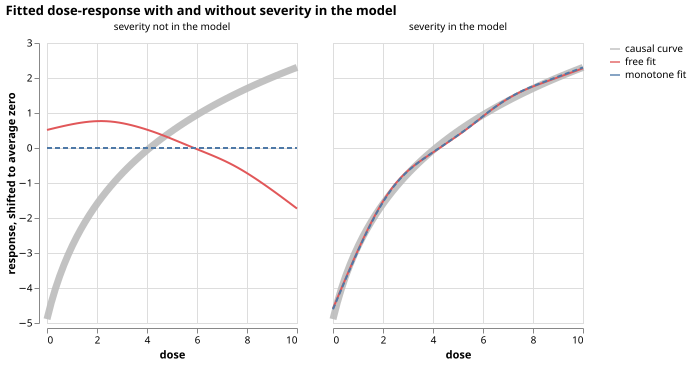

In [9]:
colour = alt.Color(
    "curve:N", title=None,
    scale=alt.Scale(domain=["causal curve", "free fit", "monotone fit"],
                    range=["#bbbbbb", "#e15759", "#4e79a7"]),
)
# The causal curve is drawn thick and underneath, and the monotone fit dashed,
# so that curves lying on top of each other stay separately visible.

truth = alt.Chart(curves).transform_filter(
    alt.datum.curve == "causal curve"
).mark_line(strokeWidth=7, opacity=0.9).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("response:Q", title="response, shifted to average zero"),
    color=colour,
)

fitted = alt.Chart(curves).transform_filter(
    alt.datum.curve != "causal curve"
).mark_line(strokeWidth=2).encode(
    x=alt.X("dose:Q"),
    y=alt.Y("response:Q"),
    color=colour,
    strokeDash=alt.condition(alt.datum.curve == "monotone fit",
                             alt.value([5, 3]), alt.value([1, 0])),
)

alt.layer(truth, fitted).properties(width=250, height=280).facet(
    column=alt.Column("panel:N", title=None, sort=panel_order),
).properties(
    title="Fitted dose-response with and without severity in the model"
)


## Comparison of the six fits

Without severity in the model, the free fit slopes downward over most of the
dose range — {eval}`none_free_falls` of the {eval}`n_intervals` plotted
intervals fall — and it sits {eval}`none_free_distance` from the causal curve.
The monotone fit is forbidden to fall, so it stops after a single iteration and
returns a flat line, {eval}`none_mono_distance` from the truth.

The free fit predicts held-out patients *better* than the monotone one (mean
squared error {eval}`none_free_mse` against {eval}`none_mono_mse`) and is
*further* from the causal curve ({eval}`none_free_distance` against
{eval}`none_mono_distance`). Severity affects both dose and outcome, so an unadjusted dose term can improve
prediction by absorbing severity's association with outcome. Its better
held-out error therefore does not imply a more accurate intervention curve.
The increasing constraint prevents the downward fit but returns a flat curve;
it does not recover the missing severity adjustment.


With severity in the model the two agree. The free fit is already monotone
there, so the constraint changes nothing: both reach {eval}`severity_mse` in
mean squared error and sit {eval}`severity_free_distance` and
{eval}`severity_mono_distance` from the causal curve. In the right panel all
three lines lie on top of one another: the two fits differ by at most
{eval}`curve_disagreement` across the dose range, on a curve that spans
{eval}`curve_span`. They are not the same model — one stops at
{eval}`severity_free_mstop` iterations and the other at
{eval}`severity_mono_mstop` — but the curves are indistinguishable, because the
free fit has no reason to fall and the constraint therefore removes nothing.


## Cross-validated cost of the constraint

Interpreting the comparison causally requires two assumptions. The first is that raising a patient's dose would never lower
their response for any patient — the monotone-response assumption
{cite}`manski1997monotone`. The second is that patients on different doses
are comparable once the adjustment set is held fixed
{cite}`pearl2009causality`. Together they require the fitted curve to be
non-decreasing, so a curve that falls is evidence against one of them. The
diagnostic does not say which.

Both versions are scored the same way. The patients are split into ten folds.
Each fold is held out in turn, the model is fitted on the other nine, and the
mean squared error on the held-out fold is recorded. The two versions use the
same folds, so the ten pairs of scores can be subtracted one fold at a time.

The gap is the difference of those paired errors: the monotone model's error
minus the free model's, averaged over the ten folds. It is positive when the
constraint costs accuracy. The reported fold-disagreement scale is the sample
standard deviation of the paired fold gaps divided by the square root of ten.
It summarizes this partition; it is not a calibrated standard error because
both stopping points were selected on these folds and fold scores share training rows.

The constrained function class is nested inside the free class, which orders
their best attainable training losses at convergence. It does not order
held-out error: a constraint can reduce sampling variance and improve
prediction. The measured gap records the net effect of the restriction,
finite sample, penalties, and stopping rule. It cannot identify which causal
assumption failed.

In [10]:
gaps = []
for adjustment in adjustments:
    difference = fold_risk[(adjustment, "monotone")] - fold_risk[(adjustment, "free")]
    error = difference.std(ddof=1) / np.sqrt(len(difference))
    gaps.append({
        "adjustment": adjustment,
        "gap": round(float(difference.mean()), 3),
        "fold disagreement": round(float(error), 3),
        "gap in units of that disagreement": round(float(difference.mean() / error), 1),
    })

display(pl.DataFrame(gaps))

gap_rows = {g["adjustment"]: g for g in gaps}
gap_none = f"{gap_rows['none']['gap']:.3f}"
gap_none_z = f"{gap_rows['none']['gap in units of that disagreement']:.1f}"
gap_proxy = f"{gap_rows['proxy']['gap']:.3f}"
gap_proxy_z = f"{gap_rows['proxy']['gap in units of that disagreement']:.1f}"
gap_severity = f"{abs(gap_rows['severity']['gap']):.3f}"


adjustment,gap,fold disagreement,gap in units of that disagreement
str,f64,f64,f64
"""none""",0.361,0.123,2.9
"""proxy""",0.042,0.046,0.9
"""severity""",-0.0,0.001,-0.4


With no confounder in the model the gap is {eval}`gap_none` in mean squared
error, {eval}`gap_none_z` times the disagreement between folds. With the proxy
it falls to {eval}`gap_proxy`, {eval}`gap_proxy_z` times that disagreement,
which is small relative to this partition's fold disagreement. With severity
itself it is {eval}`gap_severity`. In this data-generating process the gap shrinks
as the remaining confounding shrinks; that ordering is a simulation result, not
a general calibration from gap size to confounding strength.


## False-alarm and detection rates of the check

The reference rule flags a run when the mean paired gap exceeds twice its
descriptive fold-disagreement scale. Two is a visible heuristic threshold, not
a t critical value. Its behavior must therefore be measured under both
confounded and clean simulations. The fitting below is
repeated on thirty fresh data sets in three settings: confounded data with no
adjustment, the same data with severity in the model, and data in which the
dose is assigned at random.

In [11]:
def risk_gap(source, extra, fold_weights):
    per_fold = {}
    for shape, dose_term in dose_terms.items():
        model = mb.gamboost(f"y ~ {dose_term} + {covariates}{extra}", data=source,
                            family=mb.Gaussian(), control=mb.boost_control(600, 0.1))
        result = model.cvrisk(folds=fold_weights)
        average = np.asarray(result.aggregate)
        per_fold[shape] = np.asarray(result.risk_matrix)[:, int(np.argmin(average))]
    difference = per_fold["monotone"] - per_fold["free"]
    error = difference.std(ddof=1) / np.sqrt(len(difference))
    return float(difference.mean() / error) if error > 0 else 0.0
# Reuse the declared folds so comparisons differ by model, not by split.
rng = np.random.default_rng(7)

settings = {
    "confounded, no adjustment": [],
    "confounded, severity in the model": [],
    "dose assigned at random": [],
}

n_replicates = 30

for replicate in range(n_replicates):
    replicate_folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=replicate + 1)
    confounded = generate(rng)
    randomised = generate(rng, confounded=False)
    settings["confounded, no adjustment"].append(
        risk_gap(confounded, "", replicate_folds))
    settings["confounded, severity in the model"].append(
        risk_gap(confounded, adjustments["severity"], replicate_folds))
    settings["dose assigned at random"].append(
        risk_gap(randomised, "", replicate_folds))


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 597 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 593 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 600 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_67092/1795239524.py:6: RuntimeWarning: the cross-validated risk is still falling at mstop=600, the largest iteration evaluated, so the reported optimal_mstop=600 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(1200)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  result = model.cvrisk(folds=fold_weights)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 595 is within 5% of the search cap 600; the search range was exhausted — consider i

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 596 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 599 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


In [12]:
display(pl.DataFrame([
    {
        "setting": label,
        "median gap in units of fold disagreement": round(float(np.median(values)), 1),
        "runs above 2": int(np.sum(np.asarray(values) > 2)),
        "runs": len(values),
    }
    for label, values in settings.items()
]))
# Reuse the declared folds so comparisons differ by model, not by split.
fires = {label: int(np.sum(np.asarray(v) > 2)) for label, v in settings.items()}

medians = {label: f"{np.median(v):.1f}" for label, v in settings.items()}

fires_none = fires["confounded, no adjustment"]

median_none = medians["confounded, no adjustment"]

median_severity = medians["confounded, severity in the model"]

median_random = medians["dose assigned at random"]

fires_clean = (fires["confounded, severity in the model"]
               + fires["dose assigned at random"])

n_clean_runs = 2 * n_replicates


setting,median gap in units of fold disagreement,runs above 2,runs
str,f64,i64,i64
"""confounded, no adjustment""",3.7,28,30
"""confounded, severity in the mo…",-0.3,0,30
"""dose assigned at random""",-0.7,0,30


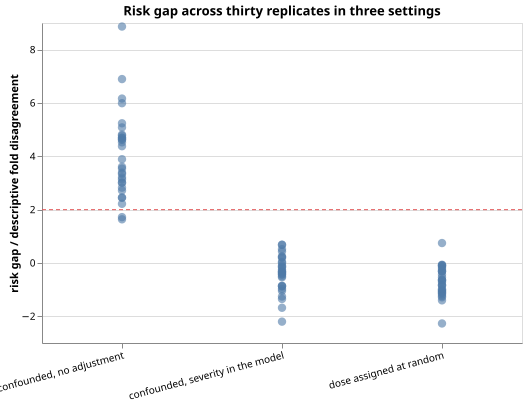

In [13]:
z_frame = pl.concat([
    pl.DataFrame({"setting": [label] * len(values), "z": values})
    for label, values in settings.items()
])
threshold = alt.Chart(pl.DataFrame({"z": [2.0]})).mark_rule(
    color="#e15759", strokeDash=[4, 3]
).encode(y="z:Q")
points = alt.Chart(z_frame).mark_circle(size=70, opacity=0.6, color="#4e79a7").encode(
    x=alt.X("setting:N", title=None, axis=alt.Axis(labelAngle=-15)),
    y=alt.Y("z:Q", title="risk gap / descriptive fold disagreement"),
)
alt.layer(points, threshold).properties(
    title="Risk gap across thirty replicates in three settings",
    width=480, height=320,
)

With no adjustment, the gap is more than twice the fold disagreement in
{eval}`fires_none` of the {eval}`n_replicates` runs, with a median of
{eval}`median_none` times. With severity in the model that happens in none of
the {eval}`n_replicates`, median {eval}`median_severity`. With the dose assigned
at random it again happens in none of the {eval}`n_replicates`, median
{eval}`median_random`. A negative median means the constrained model predicted
slightly better than the free one. In these finite runs, the heuristic did not
cross its reference line in either clean setting; more simulations and other
designs would be needed to estimate a false-alarm rate precisely.


## Effect of the constraint on the estimate

In these simulations, the constraint reduces error when confounding makes
the fitted dose curve decrease. With weak or absent confounding, it changes
little. Restricting the direction can reduce this component of bias, but
identification of the intervention curve still requires a sufficient
adjustment set. The flat line the constraint
returns when the confounder is missing ({eval}`none_mono_distance` from the
causal curve against {eval}`none_free_distance` for the free fit) is closer to
the truth than the free fall but far from the {eval}`severity_free_distance` a
model with severity reaches; with the proxy the constrained distance is
{eval}`proxy_mono_distance` against {eval}`proxy_free_distance`. Both gaps are
the part of the bias the constraint can see, and both stop an order of magnitude
short of full adjustment.

The confounding is varied through `gamma`, how hard severity pushes the
response down. `gamma = 0` leaves severity raising the dose but not the
response, so there is nothing for the constraint to remove.


In [14]:
def distance_to_causal_curve(source, dose_term, fold_weights):
    model = mb.gamboost(f"y ~ {dose_term} + bbs(proxy, df=4)", data=source,
                        family=mb.Gaussian(), control=mb.boost_control(800, 0.1))
    stopped = model[:model.cvrisk(folds=fold_weights).optimal_mstop]
    return float(np.mean(np.abs(dose_response(stopped, source) - causal_curve)))
# Reuse the declared folds so comparisons differ by model, not by split.
strength_rows = []

for gamma in (0.0, 1.0, 2.5):
    rng = np.random.default_rng(9)
    free_run, monotone_run = [], []
    for replicate in range(12):
        sample = generate(rng, rows=400, gamma=gamma)
        replicate_folds = mb.cv_weights(400, type="kfold", B=10, seed=replicate + 1)
        free_run.append(distance_to_causal_curve(
            sample, dose_terms["free"], replicate_folds))
        monotone_run.append(distance_to_causal_curve(
            sample, dose_terms["monotone"], replicate_folds))
    improvement = np.array(free_run) - np.array(monotone_run)
    strength_rows.append({
        "confounding (gamma)": gamma,
        "free fit": round(float(np.mean(free_run)), 2),
        "monotone fit": round(float(np.mean(monotone_run)), 2),
        "improvement": round(float(improvement.mean()), 3),
        "Monte Carlo standard error": round(float(improvement.std(ddof=1) / np.sqrt(len(improvement))), 3),
        "replicates improved": f"{int((improvement > 0).sum())} of {len(improvement)}",
    })

display(pl.DataFrame(strength_rows))

strength = {r["confounding (gamma)"]: r for r in strength_rows}


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(dose), covariate dose: 4 below 0.537281 (worst 0.057 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.057 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 4 below 0.537281 (worst 0.057 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.057 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 795 is within 5% of the search cap 800; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


confounding (gamma),free fit,monotone fit,improvement,Monte Carlo standard error,replicates improved
f64,f64,f64,f64,f64,str
0.0,0.12,0.12,0.006,0.006,"""7 of 12"""
1.0,0.72,0.71,0.004,0.004,"""7 of 12"""
2.5,1.72,1.43,0.285,0.028,"""12 of 12"""


In [15]:
n_strength_replicates = len(improvement)

clean_agreement = f"{abs(strength[0.0]['improvement']):.2f}"

clean_improved = strength[0.0]["replicates improved"]

mild_improved = strength[1.0]["replicates improved"]

strong_improved = strength[2.5]["replicates improved"]

strong_gain = f"{strength[2.5]['improvement']:.3f}"

strong_error = f"{strength[2.5]['Monte Carlo standard error']:.3f}"

strong_z = f"{strength[2.5]['improvement'] / strength[2.5]['Monte Carlo standard error']:.0f}"

strong_remaining = f"{strength[2.5]['monotone fit']:.2f}"


With no confounding the two fits agree to {eval}`clean_agreement` and the
constrained one is closer in {eval}`clean_improved` replicates, so the constraint makes little difference in this setting. At mild confounding it is {eval}`mild_improved`, again showing little change. At the strength used throughout this study the constrained fit is
closer in {eval}`strong_improved`, by {eval}`strong_gain` with Monte Carlo standard error
{eval}`strong_error` — {eval}`strong_z` Monte Carlo standard errors.

Confounding bends the fitted curve downward, and the constraint deletes the
part of that bend that falls below flat, so what survives is closer to the
truth. The remaining distance, {eval}`strong_remaining` averaged over the
replicates, against the {eval}`severity_free_distance` a model with severity in
it reaches, is the part of the bias the constraint cannot see.

The constraint can reduce confounding bias only when that bias produces a
curve outside the permitted shape. Confounding that biases the curve upward, or that shifts it
without changing its shape, leaves a monotone fitted curve, and the constraint
has nothing to remove.


The constraint changes how the fit allocates its iterations.
Component-wise boosting adds one base learner per iteration. When the dose
learner is not allowed to fit the downward part of the association, that part of
the response stays unexplained, and the other learners take it instead. Given
the proxy as a candidate, the free fit spends {eval}`proxy_free_dose_steps` of
its {eval}`proxy_free_total` iterations on the dose and
{eval}`proxy_free_proxy_steps` on the proxy; the constrained fit spends
{eval}`proxy_mono_dose_steps` of {eval}`proxy_mono_total` on the dose and
{eval}`proxy_mono_proxy_steps` on the proxy, and finishes
{eval}`proxy_mono_distance` from the truth instead of
{eval}`proxy_free_distance`. With the dose learner unable to fit the fall, the
proxy is the only candidate that can, so the iterations move onto it.


## Small samples with correct adjustment

Every comparison so far has had a confounder missing, which leaves the
constraint repairing something the adjustment set should have handled. The
cleaner case puts severity in the model, so both fits adjust for the confounder
correctly and the only difference between them is the constraint.

What changes instead is the sample: 150 patients rather than 600, and response
noise three times larger. A P-spline fitted to that carries real sampling error,
and the fitted curve wanders where the data happen to run against the truth,
including downward, which the treatment cannot do.

A third fit is the control. If the constraint helps only by making the fit less
flexible, then asking for a less flexible spline — `df=2` instead of `df=4` —
should do the same job.

In [16]:
def small_sample_curve(source, dose_term, fold_weights):
    model = mb.gamboost(f"y ~ {dose_term} + bbs(severity, df=4)", data=source,
                        family=mb.Gaussian(), control=mb.boost_control(600, 0.1))
    stopped = model[:model.cvrisk(folds=fold_weights).optimal_mstop]
    return dose_response(stopped, source)
# Reuse the declared folds so comparisons differ by model, not by split.
small_sample_terms = {
    "free spline": "bbs(dose, df=4)",
    "monotone spline": "bmono(dose, df=4, constraint='increasing')",
    "smoother free spline": "bbs(dose, df=2)",
}

curves_by_learner, distances = {}, {}

for label, dose_term in small_sample_terms.items():
    rng = np.random.default_rng(17)
    replicate_curves = []
    for replicate in range(30):
        sample = generate(rng, rows=150, noise=3.0)
        replicate_folds = mb.cv_weights(150, type="kfold", B=10, seed=replicate + 1)
        replicate_curves.append(small_sample_curve(sample, dose_term, replicate_folds))
    curves_by_learner[label] = replicate_curves
    distances[label] = np.array([float(np.mean(np.abs(c - causal_curve)))
                                 for c in replicate_curves])

small_rows = []


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(dose), covariate dose: 4 above 9.34418 (worst 0.07 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.07 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(dose), covariate dose: 3 above 9.52329 (worst 0.05 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- a

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(dose), covariate dose: 5 below 0.72415 (worst 0.078 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.078 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/tmp/ipykernel_67092/2387710825.py:4: RuntimeWarning: the cross-validated risk is still falling at mstop=600, the largest iteration evaluated, so the reported optimal_mstop=600 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(1200)` then `cvrisk(folds=

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 4 above 9.34418 (worst 0.07 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.07 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 3 above 9.52329 (worst 0.05 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.05 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 4 below 0.600204 and 1 above 9.90368 (worst 0.065 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.065 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 5 below 0.72415 (worst 0.078 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.078 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bmono(dose), covariate dose: 3 below 0.500235 (worst 0.053 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.053 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/formula.py:1224: UserWarning: df=2.0 equals the rank of the penalty's null space (the unpenalized part of the P-spline), which no finite lambda attains: the learner is fitted at maximum shrinkage and df= no longer sets its flexibility. Use df > 2, or center=True to remove the null space.
  learners.append(Bbs(name, **kwargs))


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 598 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


In [17]:
for label, replicate_curves in curves_by_learner.items():
    improvement = distances["free spline"] - distances[label]
    small_rows.append({
        "dose learner": label,
        "distance from the causal curve": round(float(distances[label].mean()), 3),
        "median distance": round(float(np.median(distances[label])), 3),
        "intervals where the fit falls": round(
            float(np.mean([int((np.diff(c) < -1e-8).sum()) for c in replicate_curves])), 1),
        "closer than the free spline": round(float(improvement.mean()), 3),
        "Monte Carlo standard error": round(
            float(improvement.std(ddof=1) / np.sqrt(len(improvement))), 3),
        "replicates improved": f"{int((improvement > 0).sum())} of {len(improvement)}",
    })

display(pl.DataFrame(small_rows))

# The same three learners on the full 600-patient sample at the original noise
# level, where the data are informative enough that the shape is not in doubt.

large_rows = [
    {"dose learner": label,
     "distance at 600 patients": round(
         float(np.mean(np.abs(small_sample_curve(data, dose_term, folds) - causal_curve))), 3)}
    for label, dose_term in small_sample_terms.items()
]

display(pl.DataFrame(large_rows))

# Draw the replicate whose free-spline distance is the median of the thirty, so
# the picture is a typical draw rather than the best or the worst.

median_replicate = int(np.argsort(distances["free spline"])[len(distances["free spline"]) // 2])


dose learner,distance from the causal curve,median distance,intervals where the fit falls,closer than the free spline,Monte Carlo standard error,replicates improved
str,f64,f64,f64,f64,f64,str
"""free spline""",0.622,0.568,9.6,0.0,0.0,"""0 of 30"""
"""monotone spline""",0.553,0.522,0.0,0.068,0.024,"""23 of 30"""
"""smoother free spline""",0.639,0.53,0.0,-0.018,0.051,"""13 of 30"""


dose learner,distance at 600 patients
str,f64
"""free spline""",0.073
"""monotone spline""",0.078
"""smoother free spline""",0.415


In [18]:
first_replicate = {label: curves[median_replicate]
                   for label, curves in curves_by_learner.items()}
# Compute the table or diagnostic interpreted in the following paragraph.
print(f"drawing replicate {median_replicate}, whose free-spline distance is "
      f"{distances['free spline'][median_replicate]:.2f}")

small = {r["dose learner"]: r for r in small_rows}

large = {r["dose learner"]: r for r in large_rows}

n_small_replicates = len(distances["free spline"])

free_small = f"{small['free spline']['distance from the causal curve']:.3f}"

free_small_median = f"{small['free spline']['median distance']:.3f}"

free_small_falls = f"{small['free spline']['intervals where the fit falls']:.1f}"

mono_small = f"{small['monotone spline']['distance from the causal curve']:.3f}"

mono_small_improved = small["monotone spline"]["replicates improved"]

mono_small_gain = f"{small['monotone spline']['closer than the free spline']:.3f}"

mono_small_error = f"{small['monotone spline']['Monte Carlo standard error']:.3f}"

smooth_small = f"{small['smoother free spline']['distance from the causal curve']:.3f}"

smooth_small_gain = f"{abs(small['smoother free spline']['closer than the free spline']):.3f}"

smooth_small_error = f"{small['smoother free spline']['Monte Carlo standard error']:.3f}"


drawing replicate 28, whose free-spline distance is 0.60


In [19]:
smooth_small_improved = small["smoother free spline"]["replicates improved"]

smooth_large = f"{large['smoother free spline']['distance at 600 patients']:.3f}"

free_large = f"{large['free spline']['distance at 600 patients']:.3f}"

mono_large = f"{large['monotone spline']['distance at 600 patients']:.3f}"


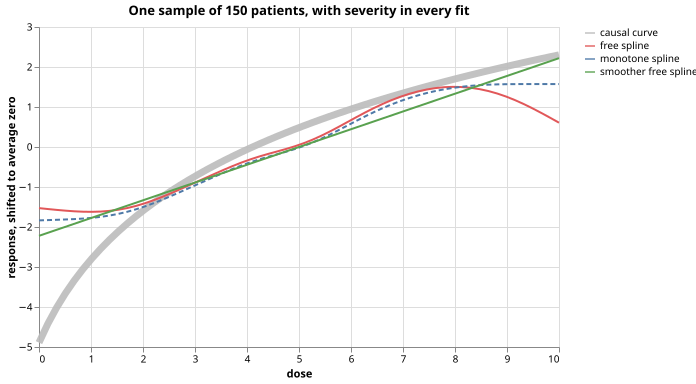

In [20]:
small_frame = pl.concat([
    pl.DataFrame({"dose": grid_dose, "response": curve, "curve": [label] * len(grid_dose)})
    for label, curve in first_replicate.items()
] + [pl.DataFrame({"dose": grid_dose, "response": causal_curve,
                   "curve": ["causal curve"] * len(grid_dose)})])
# Plot the quantities interpreted in the following paragraph.
small_colour = alt.Color(
    "curve:N", title=None,
    scale=alt.Scale(
        domain=["causal curve", "free spline", "monotone spline", "smoother free spline"],
        range=["#bbbbbb", "#e15759", "#4e79a7", "#59a14f"]),
)
small_truth = alt.Chart(small_frame).transform_filter(
    alt.datum.curve == "causal curve"
).mark_line(strokeWidth=7, opacity=0.9).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("response:Q", title="response, shifted to average zero"),
    color=small_colour,
)
small_fits = alt.Chart(small_frame).transform_filter(
    alt.datum.curve != "causal curve"
).mark_line(strokeWidth=2).encode(
    x=alt.X("dose:Q"), y=alt.Y("response:Q"), color=small_colour,
    strokeDash=alt.condition(alt.datum.curve == "monotone spline",
                             alt.value([5, 3]), alt.value([1, 0])),
)
alt.layer(small_truth, small_fits).properties(
    title="One sample of 150 patients, with severity in every fit",
    width=520, height=320,
)


The chart is the replicate at the median distance, so it is a typical draw
rather than the best or the worst. The free spline tracks the causal curve
through the middle of the range and then turns down above a dose of 8, where
the last few patients happen to sit low. The monotone spline flattens there
instead. The `df=2` spline is a straight line that misses the curvature at the
bottom of the range.

Across the {eval}`n_small_replicates` replicates the free spline sits
{eval}`free_small` from the causal curve on average, {eval}`free_small_median`
at the median, and falls on {eval}`free_small_falls` of the
{eval}`n_intervals` plotted intervals though the treatment effect rises
everywhere. The monotone spline sits {eval}`mono_small`, closer in
{eval}`mono_small_improved` replicates, by {eval}`mono_small_gain` with a
Monte Carlo standard error {eval}`mono_small_error`. Both fits adjust for severity, and
both are fitted to the same samples on the same folds; the constraint is the
only thing that differs.

The `df=2` comparison checks whether reducing flexibility produces the same
improvement. The `df=2` spline is less flexible
and cannot fall far either, and it sits at {eval}`smooth_small` —
{eval}`smooth_small_gain` *further* from the causal curve than the free spline,
with Monte Carlo standard error {eval}`smooth_small_error`, and closer in
{eval}`smooth_small_improved` replicates. Thus a smaller `df` does not reproduce the constraint's improvement in these
simulations.

The two act in different places. Lowering `df` shrinks the whole curve,
including the steep rise at low doses that the data do support: on the full
sample it sits {eval}`smooth_large` from the truth against {eval}`free_large`
for the free spline. The constraint acts only on the direction the treatment
cannot take and leaves the rest alone: on those same patients it sits at
{eval}`mono_large`, which is the free spline's {eval}`free_large` within
rounding.

The known increasing direction reduces sampling error near the sparse
boundary in these simulations while leaving the well-supported part of the
curve nearly unchanged.


## Related methods

A gap large relative to descriptive fold disagreement is evidence against three things at
once — the monotone response, the adjustment set, and the additive form of
the model — and it does not say which of them failed. The comparison checks these assumptions jointly.

The same kind of assumption can do a different job. Manski and Pepper's
monotone instrumental variable {cite}`manski2000monotone` weakens the usual
instrument condition: rather than requiring the instrument to be unrelated to
the response, it requires only that the relation run in a known direction,
which yields an interval the effect must lie in instead of a point estimate.
Here the assumption is not narrowing an answer but checking whether the model
that produced one can be right at all. That is the logic of a negative
control {cite}`lipsitch2010negative`, where a variable whose effect is
known in advance is fitted and the analysis is judged by whether it recovers
it.

## Conclusions

Knowing which way an effect must go gives a way to check a model. Fit it twice,
once with the dose effect free and once with it forbidden to fall, and see how
well each predicts patients it was not fitted to. If the constrained fit
predicts worse, the fitted data relation conflicts with at least one premise:
the response direction, the adjustment set, or the additive specification.

Under this simulation, the heuristic crossed its reference line only when the
confounder was missing. With the confounder out of
the model, the constrained fit predicted worse by {eval}`gap_none` in mean
squared error — {eval}`gap_none_z` times the disagreement between folds — and
that happened in {eval}`fires_none` of {eval}`n_replicates` repeats. With the
confounder in the model, and with the dose assigned at random, it happened in
{eval}`fires_clean` of {eval}`n_clean_runs`.

The held-out errors and distances to the known intervention curve show why
prediction accuracy alone cannot validate a causal interpretation. With severity missing, the free fit predicted held-out patients
better than the constrained one, {eval}`none_free_mse` against
{eval}`none_mono_mse`, while sitting further from the true dose-response,
{eval}`none_free_distance` against {eval}`none_mono_distance`. Out-of-sample
accuracy rose as the estimate got worse.

The constraint also bends the estimate toward the truth in the strong-confounding
runs by deleting a direction known to be impossible in the simulation. It does
not bound the remaining bias or identify the effect; those still depend on the
adjustment and structural assumptions.

The constraint cannot reduce every form of confounding bias. Confounding that bends the curve
upward, or that shifts it without changing its shape, leaves a curve the
constraint already permits, and there is nothing to delete.

A gap can reflect failure of any of three assumptions — the response rises
with the dose for every patient, the adjustment set makes patients on different
doses comparable, the effects add — and it does not say which. And all of this
is one confounder, a Gaussian response, an additive model, and a constraint
known in advance to be true; where the direction itself is in doubt, a gap has
two explanations and this comparison does not separate them.


```{bibliography}
:filter: docname in docnames
```